# Linear Regression 2.2 — FIFA World Cup 2026 Goals Prediction

## Preliminary Data Exploration and Validation

In [1]:
import pandas as pd

features = pd.read_csv("data/match_prediction_features_X.csv")

columns_to_check = [
    "date",
    "home_team_name",
    "away_team_name",
    "home_prev_avg_corners",
    "home_prev_avg_fouls",
    "home_prev_avg_offsides"
]

print(features[columns_to_check].head(15).to_string(index=False))

      date home_team_name         away_team_name  home_prev_avg_corners  home_prev_avg_fouls  home_prev_avg_offsides
2026-06-11         Mexico           South Africa                    5.0                 12.0                     2.0
2026-06-11    South Korea                Czechia                    5.0                 12.0                     2.0
2026-06-12         Canada Bosnia and Herzegovina                    5.0                 12.0                     2.0
2026-06-12            USA               Paraguay                    5.0                 12.0                     2.0
2026-06-13          Qatar            Switzerland                    5.0                 12.0                     2.0
2026-06-13         Brazil                Morocco                    5.0                 12.0                     2.0
2026-06-13          Haiti               Scotland                    5.0                 12.0                     2.0
2026-06-13      Australia                Türkiye                

In [2]:
print(
    features[columns_to_check]
    .tail(15)
    .to_string(index=False)
)

      date home_team_name away_team_name  home_prev_avg_corners  home_prev_avg_fouls  home_prev_avg_offsides
2026-07-04         Canada        Morocco               9.250000            11.750000                2.000000
2026-07-05         Brazil         Norway               5.750000             9.500000                1.500000
2026-07-06         Mexico        England               2.500000            10.750000                1.000000
2026-07-06       Portugal          Spain               5.750000             7.750000                1.750000
2026-07-07            USA        Belgium               5.000000            10.250000                1.750000
2026-07-07      Argentina          Egypt               4.250000            10.500000                2.000000
2026-07-07    Switzerland       Colombia               5.750000            10.750000                0.500000
2026-07-09         France        Morocco               7.200000             9.000000                1.800000
2026-07-10         

In [3]:
france_matches = features[
    (features["home_team_name"] == "France") |
    (features["away_team_name"] == "France")
].copy()

france_matches["france_prev_corners"] = france_matches.apply(
    lambda row: (
        row["home_prev_avg_corners"]
        if row["home_team_name"] == "France"
        else row["away_prev_avg_corners"]
    ),
    axis=1
)

print(
    france_matches[
        ["date", "home_team_name", "away_team_name", "france_prev_corners"]
    ].sort_values("date").to_string(index=False)
)

      date home_team_name away_team_name  france_prev_corners
2026-06-16         France        Senegal             5.000000
2026-06-22         France           Iraq             6.000000
2026-06-26         Norway         France             5.000000
2026-07-01         France         Sweden             5.000000
2026-07-04       Paraguay         France             6.000000
2026-07-09         France        Morocco             7.200000
2026-07-14         France          Spain             7.166667
2026-07-18         France        England             6.571429


In [4]:
france = france_matches.sort_values("date").copy()

france["previous_matches"] = range(len(france))

france["implied_corners"] = (
    france["france_prev_corners"].shift(-1)
    * (france["previous_matches"] + 1)
    - france["france_prev_corners"]
    * france["previous_matches"]
)

print(
    france[
        ["date", "france_prev_corners", "implied_corners"]
    ].to_string(index=False)
)

      date  france_prev_corners  implied_corners
2026-06-16             5.000000              6.0
2026-06-22             6.000000              4.0
2026-06-26             5.000000              5.0
2026-07-01             5.000000              9.0
2026-07-04             6.000000             12.0
2026-07-09             7.200000              7.0
2026-07-14             7.166667              3.0
2026-07-18             6.571429              NaN


In [5]:
import pandas as pd
import numpy as np


records = []

for _, row in features.iterrows():
    for side in ["home", "away"]:
        records.append({
            "date": row["date"],
            "match_id": row["match_id"],
            "team": row[f"{side}_team_name"],
            "corners": row[f"{side}_prev_avg_corners"],
            "fouls": row[f"{side}_prev_avg_fouls"],
            "offsides": row[f"{side}_prev_avg_offsides"]
        })

history = pd.DataFrame(records)
history["date"] = pd.to_datetime(history["date"])
history = history.sort_values(["team", "date", "match_id"])

results = []

for team, group in history.groupby("team"):
    group = group.reset_index(drop=True)

    for variable in ["corners", "fouls", "offsides"]:
        values = group[variable].to_numpy()

        for i in range(len(values) - 1):
            # Recover the implied statistic from successive averages
            implied = values[i + 1] * (i + 1) - values[i] * i

            results.append({
                "team": team,
                "variable": variable,
                "match_number": i + 1,
                "implied_value": implied,
                "valid": (
                    implied >= -0.0001
                    and np.isclose(implied, round(implied), atol=0.001)
                )
            })

verification = pd.DataFrame(results)

print("Total checks:", len(verification))
print("Valid checks:", verification["valid"].sum())
print("Invalid checks:", (~verification["valid"]).sum())

print("\nResults by variable:")
print(
    verification.groupby("variable")["valid"]
    .agg(["count", "sum"])
)

print("\nInvalid observations:")
print(
    verification.loc[~verification["valid"]]
    .head(20)
    .to_string(index=False)
)

Total checks: 480
Valid checks: 480
Invalid checks: 0

Results by variable:
          count  sum
variable            
corners     160  160
fouls       160  160
offsides    160  160

Invalid observations:
Empty DataFrame
Columns: [team, variable, match_number, implied_value, valid]
Index: []


In [6]:
ranking_check = pd.concat([
    features[["home_team_name", "home_fifa_rank"]].rename(
        columns={"home_team_name": "team", "home_fifa_rank": "rank"}
    ),
    features[["away_team_name", "away_fifa_rank"]].rename(
        columns={"away_team_name": "team", "away_fifa_rank": "rank"}
    )
])

print(
    ranking_check.groupby("team")["rank"]
    .first()
    .sort_values()
    .to_string()
)

team
Argentina                  1
Spain                      2
France                     3
England                    4
Portugal                   5
Brazil                     6
Morocco                    7
Netherlands                8
Belgium                    9
Germany                   10
Croatia                   11
Colombia                  13
Mexico                    14
Senegal                   15
Uruguay                   16
USA                       17
Japan                     18
Switzerland               19
IR Iran                   20
South Korea               22
Ecuador                   23
Austria                   24
Sweden                    25
Türkiye                   26
Australia                 27
Algeria                   28
Canada                    33
Panama                    34
Egypt                     36
Côte d'Ivoire             38
Scotland                  39
Czechia                   40
Norway                    44
Tunisia                   45
Ghana    

## Data Loading and Preparation

This section loads the FIFA World Cup 2026 match features and target data. Each match is transformed into two team-level observations so that the model can predict goals scored by an individual team.

In [7]:
import pandas as pd

features = pd.read_csv("data/match_prediction_features_X.csv")
targets = pd.read_csv("data/match_prediction_targets_y.csv")

print("Features shape:", features.shape)
print("Targets shape:", targets.shape)

print("\nFeatures columns:")
print(features.columns.tolist())

print("\nTargets columns:")
print(targets.columns.tolist())

Features shape: (104, 60)
Targets shape: (104, 7)

Features columns:
['match_id', 'date', 'kickoff_time_utc', 'stage_id', 'is_knockout', 'home_team_id', 'home_team_name', 'home_fifa_code', 'home_confederation', 'away_team_id', 'away_team_name', 'away_fifa_code', 'away_confederation', 'venue_id', 'stadium_name', 'venue_city', 'venue_country', 'venue_capacity', 'venue_elevation_meters', 'referee_id', 'referee_name', 'referee_avg_cards', 'home_fifa_rank', 'away_fifa_rank', 'home_elo', 'away_elo', 'home_is_host', 'away_is_host', 'home_squad_avg_age', 'away_squad_avg_age', 'home_squad_total_caps', 'away_squad_total_caps', 'home_squad_total_value_eur', 'away_squad_total_value_eur', 'home_squad_avg_value_eur', 'away_squad_avg_value_eur', 'home_rest_days', 'away_rest_days', 'home_prev_avg_goals_scored', 'home_prev_avg_goals_conceded', 'away_prev_avg_goals_scored', 'away_prev_avg_goals_conceded', 'home_prev_avg_possession', 'away_prev_avg_possession', 'home_prev_avg_shots', 'away_prev_avg_shots

## Dataset Validation

The dataset contains 208 team-match observations from 104 matches, with two observations per match.

This section checks the dataset structure, missing values, and duplicate records to ensure that the data is suitable for linear regression.

In [8]:

merged = features.merge(
    targets[["match_id", "home_score", "away_score"]],
    on="match_id",
    how="inner",
    validate="one_to_one"
)


home = pd.DataFrame({
    "match_id": merged["match_id"],
    "team": merged["home_team_name"],
    "team_fifa_rank": merged["home_fifa_rank"],
    "opponent_fifa_rank": merged["away_fifa_rank"],
    "team_rest_days": merged["home_rest_days"],
    "opponent_rest_days": merged["away_rest_days"],
    "venue_elevation_meters": merged["venue_elevation_meters"],
    "team_prev_avg_corners": merged["home_prev_avg_corners"],
    "team_prev_avg_fouls": merged["home_prev_avg_fouls"],
    "team_prev_avg_offsides": merged["home_prev_avg_offsides"],
    "goals_scored": merged["home_score"]
})

away = pd.DataFrame({
    "match_id": merged["match_id"],
    "team": merged["away_team_name"],
    "team_fifa_rank": merged["away_fifa_rank"],
    "opponent_fifa_rank": merged["home_fifa_rank"],
    "team_rest_days": merged["away_rest_days"],
    "opponent_rest_days": merged["home_rest_days"],
    "venue_elevation_meters": merged["venue_elevation_meters"],
    "team_prev_avg_corners": merged["away_prev_avg_corners"],
    "team_prev_avg_fouls": merged["away_prev_avg_fouls"],
    "team_prev_avg_offsides": merged["away_prev_avg_offsides"],
    "goals_scored": merged["away_score"]
})

lr22_df = pd.concat([home, away], ignore_index=True)


lr22_df = lr22_df.sort_values(
    ["match_id", "team"]
).reset_index(drop=True)


print("Dataset shape:", lr22_df.shape)
print("Unique matches:", lr22_df["match_id"].nunique())
print("Missing values:", lr22_df.isnull().sum().sum())

display(lr22_df.head(10))

Dataset shape: (208, 11)
Unique matches: 104
Missing values: 0


,match_id,team,team_fifa_rank,opponent_fifa_rank,team_rest_days,opponent_rest_days,venue_elevation_meters,team_prev_avg_corners,team_prev_avg_fouls,team_prev_avg_offsides,goals_scored
0,1,Mexico,14,60,10.0,10.0,2200.0,5.0,12.0,2.0,2
1,1,South Africa,60,14,10.0,10.0,2200.0,5.0,12.0,2.0,0
2,2,Czechia,40,22,10.0,10.0,1566.0,5.0,12.0,2.0,1
3,2,South Korea,22,40,10.0,10.0,1566.0,5.0,12.0,2.0,2
4,3,Bosnia and Herzegovina,64,33,10.0,10.0,76.0,5.0,12.0,2.0,1
5,3,Canada,33,64,10.0,10.0,76.0,5.0,12.0,2.0,1
6,4,Paraguay,54,17,10.0,10.0,30.0,5.0,12.0,2.0,1
7,4,USA,17,54,10.0,10.0,30.0,5.0,12.0,2.0,4
8,5,Qatar,56,19,10.0,10.0,8.0,5.0,12.0,2.0,1
9,5,Switzerland,19,56,10.0,10.0,8.0,5.0,12.0,2.0,1


In [9]:
predictors = [
    "team_fifa_rank",
    "opponent_fifa_rank",
    "team_rest_days",
    "opponent_rest_days",
    "venue_elevation_meters",
    "team_prev_avg_corners",
    "team_prev_avg_fouls",
    "team_prev_avg_offsides"
]

print("Total rows:", len(lr22_df))
print("Unique matches:", lr22_df["match_id"].nunique())
print("Number of predictors:", len(predictors))
print("Missing values:", lr22_df.isna().sum().sum())
print("Duplicate team-match rows:",
      lr22_df.duplicated(["match_id", "team"]).sum())

print("\nObservations per match:")
print(lr22_df.groupby("match_id").size().value_counts())

print("\nTarget summary:")
print(lr22_df["goals_scored"].describe())

assert len(lr22_df) == 208
assert lr22_df["match_id"].nunique() == 104
assert len(predictors) == 8
assert lr22_df.isna().sum().sum() == 0
assert lr22_df.groupby("match_id").size().eq(2).all()
assert not lr22_df.duplicated(["match_id", "team"]).any()
assert (lr22_df["goals_scored"] >= 0).all()

print("\nAll structural validation checks passed!")

Total rows: 208
Unique matches: 104
Number of predictors: 8
Missing values: 0
Duplicate team-match rows: 0

Observations per match:
2    104
Name: count, dtype: int64

Target summary:
count    208.000000
mean       1.480769
std        1.393434
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: goals_scored, dtype: float64

All structural validation checks passed!


In [10]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)

lr22_df.to_csv(
    "data/linear_regression_2_2_dataset.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


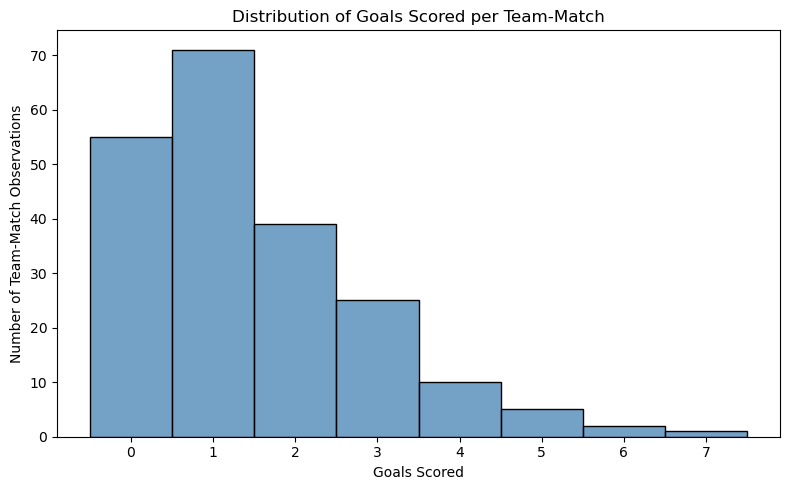

Graph saved successfully!


In [11]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

Path("outputs").mkdir(exist_ok=True)

plt.figure(figsize=(8, 5))

sns.histplot(
    lr22_df["goals_scored"],
    bins=range(0, 9),
    discrete=True,
    color="steelblue"
)

plt.title("Distribution of Goals Scored per Team-Match")
plt.xlabel("Goals Scored")
plt.ylabel("Number of Team-Match Observations")

plt.tight_layout()


plt.savefig(
    "outputs/lr22_goals_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")

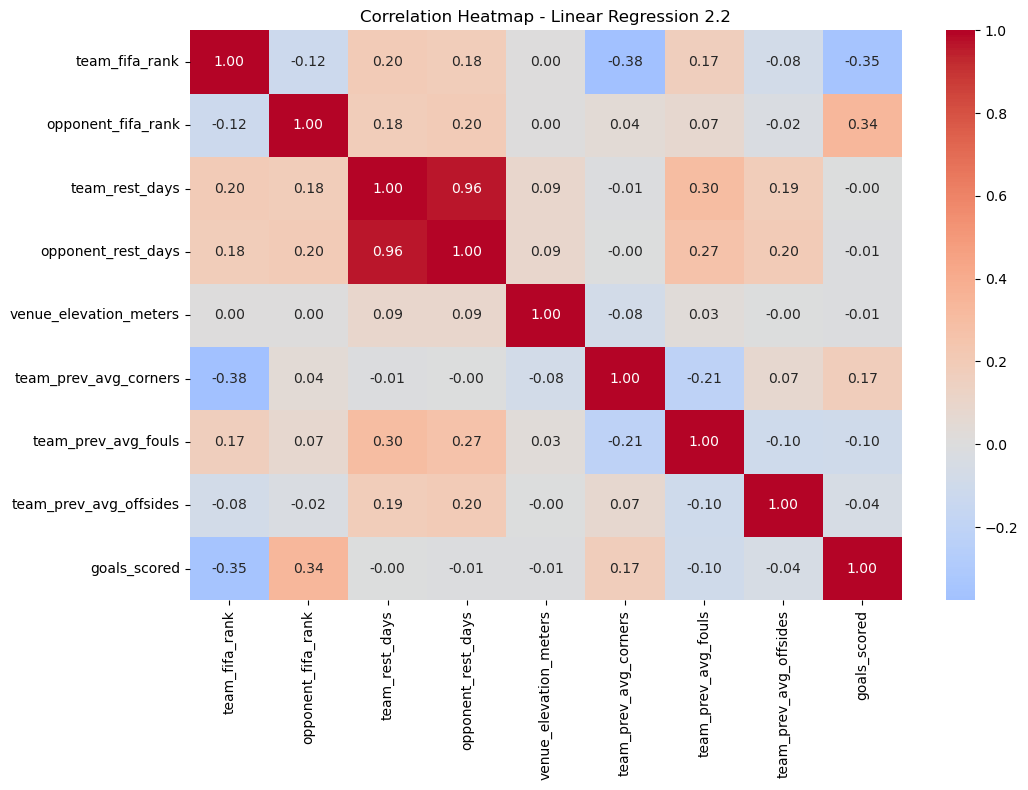

Correlation heatmap saved successfully!


In [12]:
corr_data = lr22_df[predictors + ["goals_scored"]]

correlation_matrix = corr_data.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap - Linear Regression 2.2")
plt.tight_layout()

plt.savefig(
    "outputs/lr22_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved successfully!")

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import pandas as pd

X_vif = sm.add_constant(lr22_df[predictors])

vif_table = pd.DataFrame({
    "Variable": predictors,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
})

print("Variance Inflation Factor (VIF)")
display(vif_table.sort_values("VIF", ascending=False))

Variance Inflation Factor (VIF)


,Variable,VIF
2,team_rest_days,14.058923
3,opponent_rest_days,13.850650
0,team_fifa_rank,1.270307
5,team_prev_avg_corners,1.226114
6,team_prev_avg_fouls,1.189953
7,team_prev_avg_offsides,1.090151
1,opponent_fifa_rank,1.078146
4,venue_elevation_meters,1.017248


In [14]:
candidate_df = lr22_df.merge(
    features[["match_id", "referee_avg_cards"]],
    on="match_id",
    how="left",
    validate="many_to_one"
)

print("Missing values:",
      candidate_df["referee_avg_cards"].isna().sum())

print("\nCorrelations with important variables:")

print(
    candidate_df[
        ["referee_avg_cards", "team_rest_days",
         "goals_scored"]
    ].corr()
)

print("\nReferee average cards summary:")
print(candidate_df["referee_avg_cards"].describe())

Missing values: 0

Correlations with important variables:
                   referee_avg_cards  team_rest_days  goals_scored
referee_avg_cards           1.000000       -0.114165      0.027649
team_rest_days             -0.114165        1.000000     -0.004825
goals_scored                0.027649       -0.004825      1.000000

Referee average cards summary:
count    208.000000
mean       4.283654
std        0.643828
min        2.900000
25%        3.900000
50%        4.200000
75%        4.800000
max        5.500000
Name: referee_avg_cards, dtype: float64


# Final Explanatory Variable Selection

Eight explanatory variables were selected to predict goals scored by a team.

The variables represent team and opponent rankings, team recovery time, venue conditions, previous match statistics, and referee characteristics.

The final selection avoids using the same explanatory variables as Linear Regression 2.1. An earlier candidate, opponent rest days, was replaced because of high multicollinearity with team rest days.

## Multicollinearity Analysis (VIF)

Variance Inflation Factor (VIF) was used to assess multicollinearity among the explanatory variables.

During preliminary analysis, opponent rest days showed high multicollinearity with team rest days and was removed from the final model.

The final eight explanatory variables had a maximum VIF of approximately 1.29, indicating low multicollinearity.

This suggests that the final explanatory variables can be used together without substantial multicollinearity concerns.

In [15]:
lr22_df = candidate_df.drop(
    columns=["opponent_rest_days"]
).copy()

predictors = [
    "team_fifa_rank",
    "opponent_fifa_rank",
    "team_rest_days",
    "venue_elevation_meters",
    "team_prev_avg_corners",
    "team_prev_avg_fouls",
    "team_prev_avg_offsides",
    "referee_avg_cards"
]

X_vif = sm.add_constant(lr22_df[predictors])

vif_table = pd.DataFrame({
    "Variable": predictors,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
})

print("Updated dataset shape:", lr22_df.shape)
print("\nUpdated VIF results:")
display(vif_table.sort_values("VIF", ascending=False))

Updated dataset shape: (208, 11)

Updated VIF results:


,Variable,VIF
2,team_rest_days,1.293665
0,team_fifa_rank,1.271216
4,team_prev_avg_corners,1.242583
5,team_prev_avg_fouls,1.184200
6,team_prev_avg_offsides,1.093963
1,opponent_fifa_rank,1.070828
7,referee_avg_cards,1.037004
3,venue_elevation_meters,1.020594


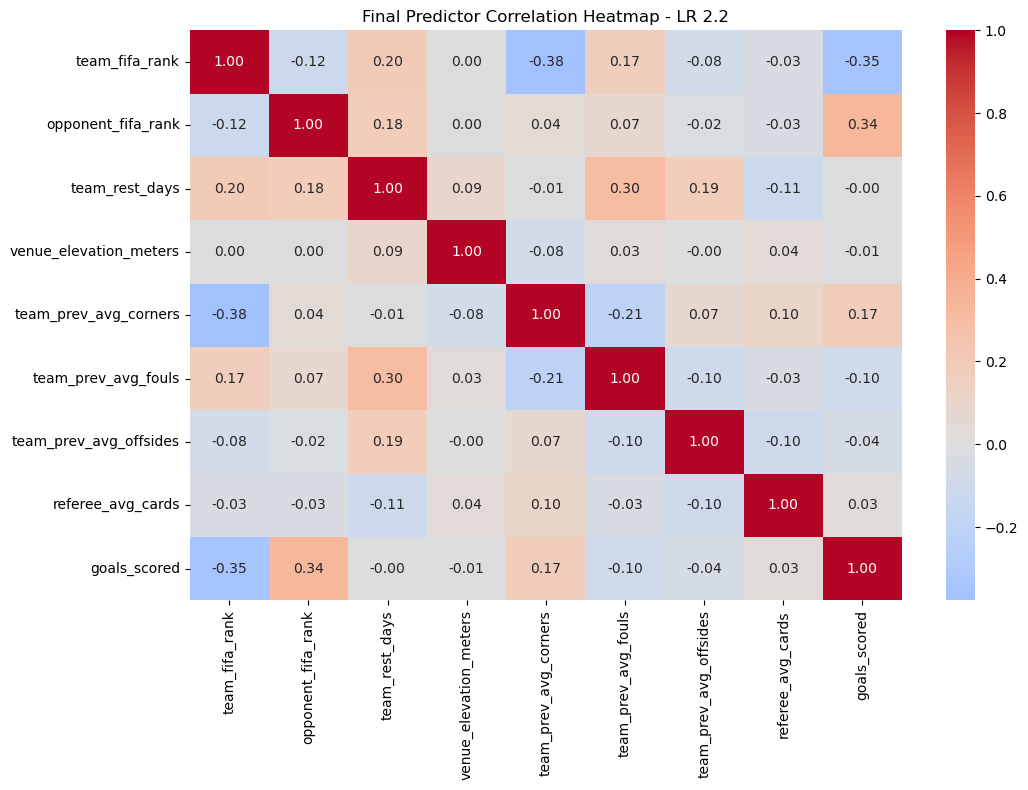

Updated dataset and heatmap saved successfully!


In [16]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

lr22_df.to_csv(
    "data/linear_regression_2_2_dataset.csv",
    index=False
)

correlation_matrix = lr22_df[
    predictors + ["goals_scored"]
].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Final Predictor Correlation Heatmap - LR 2.2")
plt.tight_layout()

plt.savefig(
    "outputs/lr22_correlation_heatmap_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Updated dataset and heatmap saved successfully!")

## Train-Test Split and Model Training

The dataset was divided into 80% training data and 20% testing data using GroupShuffleSplit.

- Training data: 166 team-match observations (83 matches)
- Testing data: 42 team-match observations (21 matches)

The split was grouped by match ID to ensure that observations from the same match did not appear in both training and testing sets, preventing match-level data leakage.

A multiple linear regression model was trained using the eight selected explanatory variables to predict goals scored.

In [17]:
from sklearn.model_selection import GroupShuffleSplit

X = lr22_df[predictors]

y = lr22_df["goals_scored"]

groups = lr22_df["match_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_matches = set(groups.iloc[train_idx])
test_matches = set(groups.iloc[test_idx])

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training matches:", len(train_matches))
print("Testing matches:", len(test_matches))
print("Shared matches:", len(train_matches & test_matches))

Training observations: 166
Testing observations: 42
Training matches: 83
Testing matches: 21
Shared matches: 0


## Model Performance Evaluation

The Linear Regression model was evaluated using three performance metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted goals.
- **RMSE (Root Mean Squared Error):** Measures prediction error while giving greater weight to large errors.
- **R² (Coefficient of Determination):** Measures the proportion of variation in goals scored explained by the model.

### Model Results

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 0.8998 | 1.1427 |
| RMSE | 1.1672 | 1.4277 |
| R² | 0.2448 | 0.1578 |

### Interpretation

The testing MAE of 1.1427 indicates that predictions differ from actual goals by approximately 1.14 goals on average.

The testing R² of 0.1578 indicates that the model explains approximately 15.78% of the variation in goals scored in the test dataset.

The lower testing performance compared with training performance suggests some generalisation difficulty. Overall, the model has limited predictive accuracy.

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lr22_model = LinearRegression()
lr22_model.fit(X_train, y_train)

y_train_pred = lr22_model.predict(X_train)
y_test_pred = lr22_model.predict(X_test)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("LINEAR REGRESSION 2.2 - MODEL PERFORMANCE")
print("-----------------------------------------")

print("\nTraining Results:")
print(f"MAE:  {train_mae:.4f}")
print(f"RMSE: {train_rmse:.4f}")
print(f"R²:   {train_r2:.4f}")

print("\nTesting Results:")
print(f"MAE:  {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R²:   {test_r2:.4f}")

LINEAR REGRESSION 2.2 - MODEL PERFORMANCE
-----------------------------------------

Training Results:
MAE:  0.8998
RMSE: 1.1672
R²:   0.2448

Testing Results:
MAE:  1.1427
RMSE: 1.4277
R²:   0.1578


## Actual vs Predicted Goals

This scatter plot compares the actual goals scored by teams with the goals predicted by the Linear Regression model.

The dashed diagonal line represents perfect predictions, where predicted goals equal actual goals.

Points closer to this line indicate more accurate predictions, while points farther away represent larger prediction errors.

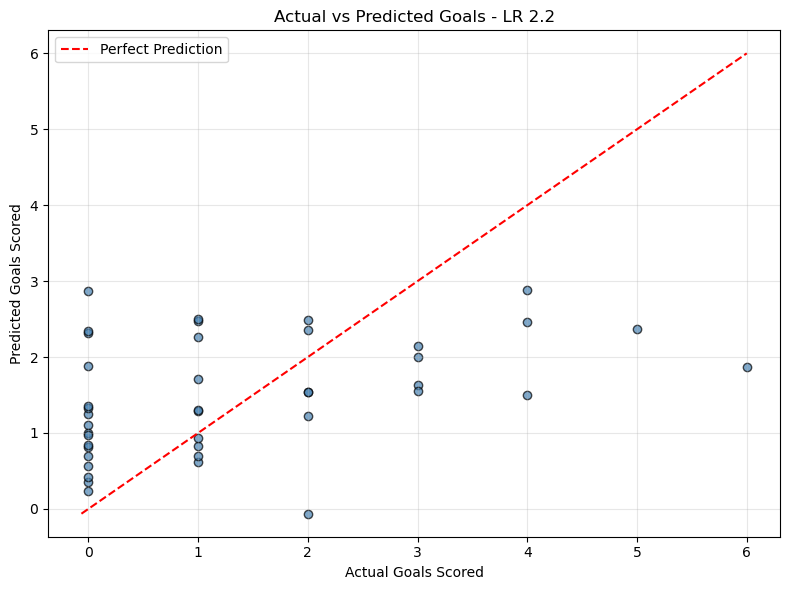

Model results and graph saved successfully!


In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Path("outputs").mkdir(exist_ok=True)

performance = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse],
    "R2": [train_r2, test_r2]
})

performance.to_csv(
    "outputs/lr22_model_performance.csv",
    index=False
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.7,
    color="steelblue",
    edgecolors="black"
)

limits = [
    min(y_test.min(), y_test_pred.min()),
    max(y_test.max(), y_test_pred.max())
]

plt.plot(
    limits,
    limits,
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Goals Scored")
plt.ylabel("Predicted Goals Scored")
plt.title("Actual vs Predicted Goals - LR 2.2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/lr22_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model results and graph saved successfully!")

## Residual Analysis

Residual analysis was performed to examine the prediction errors of the Linear Regression model.

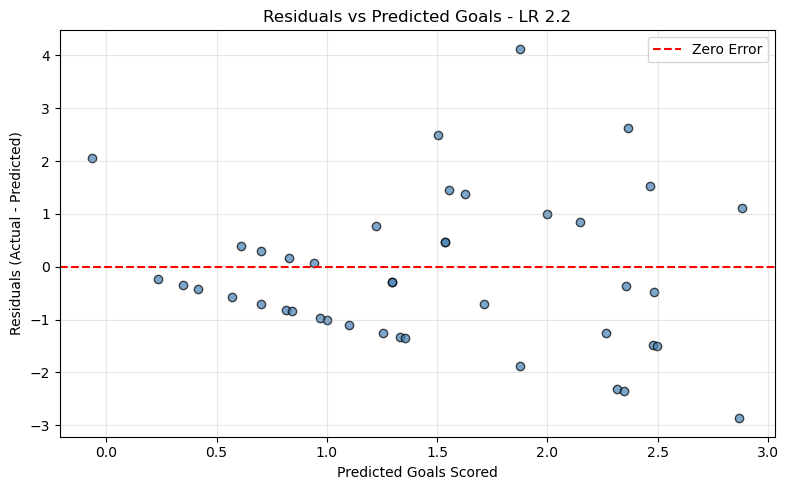

Residual plot saved successfully!


In [20]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.7,
    color="steelblue",
    edgecolors="black"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Predicted Goals Scored")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals vs Predicted Goals - LR 2.2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/lr22_residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Residual plot saved successfully!")

## Regression Coefficients and Statistical Significance

This section examines the regression coefficients of the final Linear Regression model to understand how each explanatory variable influences the predicted number of goals scored.

A positive coefficient indicates that an increase in the explanatory variable is associated with an increase in predicted goals, while a negative coefficient indicates a decrease, holding other variables constant.

Statistical significance is evaluated using p-values from Ordinary Least Squares (OLS) regression with standard errors clustered by match. A p-value below 0.05 indicates statistical significance at the 5% level.

The results help identify which explanatory variables have statistically significant relationships with goals scored.

In [21]:
coefficients = pd.DataFrame({
    "Predictor": predictors,
    "Coefficient": lr22_model.coef_
})

coefficients = coefficients.sort_values(
    "Coefficient",
    ascending=False
)

print("Model Intercept:", round(lr22_model.intercept_, 4))

print("\nLinear Regression 2.2 Coefficients:")
display(coefficients)

coefficients.to_csv(
    "outputs/lr22_coefficients.csv",
    index=False
)

print("Coefficients saved successfully!")

Model Intercept: 1.4919

Linear Regression 2.2 Coefficients:


,Predictor,Coefficient
7,referee_avg_cards,0.082841
2,team_rest_days,0.051601
1,opponent_fifa_rank,0.019681
4,team_prev_avg_corners,0.004608
3,venue_elevation_meters,-0.000032
0,team_fifa_rank,-0.019104
5,team_prev_avg_fouls,-0.049145
6,team_prev_avg_offsides,-0.098978


Coefficients saved successfully!


In [22]:
import statsmodels.api as sm

X_train_ols = sm.add_constant(X_train)

ols_model = sm.OLS(
    y_train,
    X_train_ols
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": groups.iloc[train_idx]
    }
)

print(ols_model.summary())

with open("outputs/lr22_ols_summary.txt", "w") as file:
    file.write(ols_model.summary().as_text())

print("\nOLS summary saved successfully!")

                            OLS Regression Results                            
Dep. Variable:           goals_scored   R-squared:                       0.245
Model:                            OLS   Adj. R-squared:                  0.206
Method:                 Least Squares   F-statistic:                     7.545
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.67e-07
Time:                        13:49:20   Log-Likelihood:                -261.21
No. Observations:                 166   AIC:                             540.4
Df Residuals:                     157   BIC:                             568.4
Df Model:                           8                                         
Covariance Type:              cluster                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      1

In [23]:
test_results = lr22_df.iloc[test_idx][
    ["match_id", "team", "goals_scored"]
].copy()

test_results["predicted_goals"] = y_test_pred

test_results["residual"] = (
    test_results["goals_scored"] -
    test_results["predicted_goals"]
)

test_results["absolute_error"] = (
    test_results["residual"].abs()
)

test_results.to_csv(
    "outputs/lr22_test_predictions.csv",
    index=False
)

print("Test prediction results saved successfully!")

print("\nFirst 10 predictions:")
display(test_results.head(10))

print("\nNumber of negative predictions:",
      (test_results["predicted_goals"] < 0).sum())

Test prediction results saved successfully!

First 10 predictions:


,match_id,team,goals_scored,predicted_goals,residual,absolute_error
0,1,Mexico,2,2.484311,-0.484311,0.484311
1,1,South Africa,0,0.700205,-0.700205,0.700205
8,5,Qatar,1,0.828745,0.171255,0.171255
9,5,Switzerland,1,2.263787,-1.263787,1.263787
20,11,Côte d'Ivoire,1,1.295452,-0.295452,0.295452
21,11,Ecuador,0,1.877226,-1.877226,1.877226
24,13,Cabo Verde,0,0.348727,-0.348727,0.348727
25,13,Spain,0,2.869746,-2.869746,2.869746
36,19,Algeria,0,1.100680,-1.100680,1.100680
37,19,Argentina,3,2.147873,0.852127,0.852127



Number of negative predictions: 1


## Referee Data Verification and Limitations

The referee_avg_cards variable was examined to assess its consistency across matches.

The analysis checks the number of unique referees, the number of matches assigned to each referee, and the number of distinct average-card values recorded for each referee.

The dataset contains 28 unique referees. The consistency checks help assess the reliability of the recorded values.

However, these checks cannot independently confirm whether the referee averages were calculated using historical information available before each match. This remains a limitation of the analysis.

In [24]:
referee_check = features[
    ["referee_id", "referee_name", "date",
     "match_id", "referee_avg_cards"]
].copy()

referee_check = referee_check.sort_values(
    ["referee_id", "date", "match_id"]
)

print("Unique referees:",
      referee_check["referee_id"].nunique())

print("\nMatches per referee:")
display(
    referee_check.groupby("referee_name")
    .agg(
        matches=("match_id", "count"),
        unique_card_averages=("referee_avg_cards", "nunique")
    )
    .sort_values("matches", ascending=False)
    .head(15)
)

print("\nExample referee records:")
display(referee_check.head(15))

Unique referees: 28

Matches per referee:


,matches,unique_card_averages
referee_name,,
César Arturo Ramos,5,1
Maurizio Mariani,5,1
João Pinheiro,5,1
Jesús Valenzuela,4,1
Jalal Jayed,4,1
Wilton Sampaio,4,1
Victor Gomes,4,1
Slavko Vinčić,4,1
Mustapha Ghorbal,4,1



Example referee records:


,referee_id,referee_name,date,match_id,referee_avg_cards
5,1,Szymon Marciniak,2026-06-13,6,4.2
26,1,Szymon Marciniak,2026-06-18,27,4.2
94,1,Szymon Marciniak,2026-07-07,95,4.2
0,2,Daniele Orsato,2026-06-11,1,4.8
6,2,Daniele Orsato,2026-06-13,7,4.8
27,2,Daniele Orsato,2026-06-18,28,4.8
54,2,Daniele Orsato,2026-06-25,55,4.8
28,3,Michael Oliver,2026-06-19,29,3.9
55,3,Michael Oliver,2026-06-25,56,3.9
89,3,Michael Oliver,2026-07-04,90,3.9


In [25]:
referee_summary = (
    features.groupby(["referee_id", "referee_name"])
    .agg(
        matches=("match_id", "count"),
        unique_averages=("referee_avg_cards", "nunique")
    )
    .reset_index()
)

print("Total referees:", len(referee_summary))

print(
    "Referees with changing averages:",
    (referee_summary["unique_averages"] > 1).sum()
)

print(
    "Referees with constant averages:",
    (referee_summary["unique_averages"] == 1).sum()
)

display(referee_summary)

Total referees: 28
Referees with changing averages: 0
Referees with constant averages: 28


,referee_id,referee_name,matches,unique_averages
0,1,Szymon Marciniak,3,1
1,2,Daniele Orsato,4,1
2,3,Michael Oliver,4,1
3,4,Anthony Taylor,4,1
4,5,Clément Turpin,4,1
5,6,Danny Makkelie,4,1
6,7,Jesús Valenzuela,4,1
7,8,Wilton Sampaio,4,1
8,9,César Arturo Ramos,5,1
9,10,Ivan Barton,4,1


In [26]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

vif_table.to_csv(
    "outputs/lr22_vif_results.csv",
    index=False
)

print("Final VIF table saved successfully!")
print("Maximum VIF:", round(vif_table["VIF"].max(), 4))

Final VIF table saved successfully!
Maximum VIF: 1.2937


## Conclusion

This project developed a Linear Regression model to predict the number of goals scored by each team in FIFA World Cup 2026 matches.

The final model used 208 team-match observations from 104 matches and eight explanatory variables. These variables included team and opponent FIFA rankings, team rest days, venue elevation, previous match statistics, and referee average cards.

The dataset was divided into training and testing sets using match-level grouping to prevent observations from the same match appearing in both sets.

The model achieved a test Mean Absolute Error (MAE) of 1.1427, Root Mean Squared Error (RMSE) of 1.4277, and R-squared (R²) of 0.1578.

The results indicate that the model explains approximately 15.78% of the variation in goals scored in the test dataset. Team and opponent FIFA rankings were statistically significant predictors, while the remaining variables did not show statistically significant relationships at the 5% level.

The final VIF analysis indicated low multicollinearity among the selected explanatory variables.

Overall, the model provides a baseline for predicting goals scored, although its predictive accuracy is limited. Future improvements could involve additional historical performance variables, more training data, and alternative modelling techniques.